# 06 · EDA de los splits de M3DI — train, val y test

**Pregunta.** ¿Son train ($n=125\,000$), val ($n=10\,000$) y test ($n=10\,000$) muestras de la misma
distribución, sin fugas entre ellos, y qué implica su estructura para el entrenamiento y la evaluación?

El notebook 01 analiza a fondo **un** split (test: vocabulario, mapeo código → palabra, verificación en píxel).
Aquí el foco es la **comparación entre splits**, que es lo que sostiene la etapa 2: se entrena en train, se
elige el checkpoint en val y se reporta en test. Solo lee `data/manifests/` (y, si están, las imágenes) y
escribe en `reports/{figures,tables}/eda_splits/`.

| § | Pregunta | Por qué importa |
|---|---|---|
| 1 | ¿Los tres manifiestos están completos y son consistentes? | Base de todo lo demás |
| 2 | ¿Hay fuga entre splits (escenas o captions repetidos)? | Test debe medir generalización, no memoria |
| 3 | ¿Coinciden latentes de imagen y de texto en cada split? | Techo de exactitud por atributo |
| 4 | ¿Forma, posición, color y plantilla se distribuyen igual en los tres? | Cambio de distribución train → test |
| 5 | ¿Cómo se cubren las 63 combinaciones forma × posición? | Split composicional (`data.holdout`) |
| 6 | ¿Los latentes continuos (rotación, foco, fondo) son homogéneos? | Factores no descritos que afectan la percepción |
| 7 | ¿Cómo se relacionan nombre de color, matiz y categoría básica? | Por qué el "nombre exacto" es inalcanzable |
| 8 | ¿Cuántos textos distintos hay (original y canónico)? | Bancos de recuperación de VL-JEPA y objetivo de la etapa 2 |
| 9 | ¿Hay dependencias (atajos) entre atributos? | Un modelo podría acertar uno a partir de otro |
| 10 | ¿Cuál es la exactitud de azar con la marginal de train? | Línea base para los "puntos sobre azar" |
| 11 | Inspección visual por split | Control a ojo |
| 12 | Resumen de hallazgos | Para el informe |

## 0. Configuración

In [ ]:
import math
import random
import sys
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import Markdown, display
from PIL import Image
from scipy import stats
from scipy.spatial import cKDTree

try:
    from vlmfid.paths import ROOT
except ImportError:  # kernel sin el paquete instalado en modo editable
    sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
    from vlmfid.paths import ROOT
from vlmfid.data import SPLITS, data_root, read_manifest, to_records
from vlmfid.data.targets import CANONICAL_TEMPLATE, HELD_OUT_COMBOS, canonical_caption
from vlmfid.eval.attributes import (
    COLOR_CATS,
    HUE_UPPER,
    SHAPE_NAMES,
    XPOS_NAMES,
    YPOS_NAMES,
    hue_to_cat,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 180, "display.max_columns", 40, "display.precision", 4)

# ── Parámetros ───────────────────────────────────────────────────────────────
VARIANT = "base"
SEED = 0
BANK_MAX_CAPTIONS, BANK_SEED = 20_000, 0  # banco de VL-JEPA (configs/models/vljepa.yaml → bank)
N_IMG_CHECK = 50  # imágenes por split para verificar que existen
N_IMG_SHOW = 6  # imágenes por split en la galería (§11)

FIG_DIR = ROOT / "reports" / "figures" / "eda_splits"
TAB_DIR = ROOT / "reports" / "tables" / "eda_splits"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
print("ROOT =", ROOT)

ROOT = C:\Users\bruno\Documents\MDS\Redes_Neuronales_Teoria_Informacion\Proyecto T7


In [ ]:
# ── Estilo (mismo sistema que los notebooks 02-05) ──
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, INK3, GRID, SURF, NEUTRAL = (
    "#0b0b0b",
    "#52514e",
    "#8a8984",
    "#e6e5e1",
    "#fcfcfb",
    "#c9c8c2",
)
SEQ = mcolors.LinearSegmentedColormap.from_list(
    "seq_blue",
    ["#f4f8fe", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
)
SPLIT_COLORS = {"train": SERIES[0], "val": SERIES[1], "test": SERIES[2]}
CAT_COLORS = {
    "red": "#d62728",
    "orange": "#ff8c1a",
    "yellow": "#e6c700",
    "green": "#2ca02c",
    "cyan": "#17becf",
    "blue": "#1f4fd6",
    "purple": "#7b3fb5",
    "pink": "#e377c2",
}

plt.rcParams.update(
    {
        "figure.facecolor": SURF,
        "axes.facecolor": SURF,
        "savefig.facecolor": SURF,
        "axes.edgecolor": INK3,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 10.5,
        "axes.titleweight": "semibold",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "font.size": 9.5,
        "lines.linewidth": 2,
        "lines.markersize": 7,
        "figure.dpi": 110,
    }
)
PCT = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
FINDINGS = []


def note(section, text):
    FINDINGS.append((section, text))
    print(f"• [{section}] {text}")


def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=200, bbox_inches="tight")


def save_table(df, name, index=True, float_format="%.4f"):
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)
    try:
        df.to_latex(
            TAB_DIR / f"{name}.tex",
            index=index,
            float_format=float_format,
            escape=True,
            na_rep="--",
        )
    except Exception as e:  # to_latex requiere jinja2
        print(f"[aviso] {name}.tex no generado: {e}")


def heat(
    ax, M, xlabels, ylabels, fmt="{:.0%}", vmin=None, vmax=None, cmap=SEQ, fontsize=8, marks=None
):
    # Mapa de calor anotado; `marks` (matriz booleana) enmarca celdas.
    M = np.asarray(M, dtype=float)
    norm = mcolors.Normalize(
        vmin=np.nanmin(M) if vmin is None else vmin, vmax=np.nanmax(M) if vmax is None else vmax
    )
    ax.imshow(M, cmap=cmap, norm=norm, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            r, g, b, _ = cmap(norm(M[i, j]))
            lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
            ax.text(
                j,
                i,
                fmt.format(M[i, j]),
                ha="center",
                va="center",
                fontsize=fontsize,
                color="white" if lum < 0.5 else INK,
            )
            if marks is not None and marks[i][j]:
                ax.add_patch(
                    plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=SERIES[7], lw=2)
                )
    ax.set_xticks(range(M.shape[1]), xlabels)
    ax.set_yticks(range(M.shape[0]), ylabels)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)


# ── Teoría de la información y contrastes ──
def entropy_bits(v):
    _, c = np.unique(v, return_counts=True)
    p = c / c.sum()
    return float(-(p * np.log2(p)).sum())


def contingency(a, b):
    _, ai = np.unique(a, return_inverse=True)
    _, bi = np.unique(b, return_inverse=True)
    tab = np.zeros((ai.max() + 1, bi.max() + 1))
    np.add.at(tab, (ai, bi), 1)
    return tab


def mutual_info_bits(a, b):
    p = contingency(a, b)
    p /= p.sum()
    pa, pb = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return float((p[nz] * np.log2(p[nz] / (pa @ pb)[nz])).sum())


def jsd_bits(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2

    def kl(a, b):
        nz = a > 0
        return float((a[nz] * np.log2(a[nz] / b[nz])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def homogeneity(tab):
    # χ² de homogeneidad split × valor y V de Cramér (efecto, independiente de n).
    tab = np.asarray(tab, float)
    tab = tab[:, tab.sum(0) > 0]
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v = math.sqrt(chi2 / (tab.sum() * (min(tab.shape) - 1)))
    return chi2, p, dof, v

## 1. Carga e integridad de los tres manifiestos

`read_manifest` lee `data/manifests/m3di_base_<split>.parquet`. Las columnas sin prefijo son latentes de
**imagen** (lo que se renderizó); las con prefijo `text_` son latentes de **texto** (de donde sale el caption).
Se construye además, por fila, lo que usa el resto del pipeline: celda de posición, categoría básica de color
(`hue_to_cat`, la verdad de la métrica "color"), caption canónico de la etapa 2 y si la combinación forma ×
posición pertenece al split composicional.

In [ ]:
RAW = {s: read_manifest(s, variant=VARIANT) for s in SPLITS}
for s, d in RAW.items():
    print(f"{s:5s}  {d.height:>7,} filas × {d.width} columnas")
print()
print(
    pd.DataFrame(
        {"tipo": [str(t) for t in RAW["train"].schema.values()]}, index=RAW["train"].columns
    ).T.to_string()
)


def derive(d: pl.DataFrame) -> pd.DataFrame:
    g = lambda c: d[c].to_numpy()
    out = pd.DataFrame(
        {
            "id": d["id"].to_list(),
            "image_path": d["image_path"].to_list(),
            "caption": d["caption_ref"].to_list(),
            "shape": g("object_shape"),
            "x": g("object_xpos"),
            "y": g("object_ypos"),
            "z": g("object_zpos"),
            "t_shape": g("text_object_shape"),
            "t_x": g("text_object_xpos"),
            "t_y": g("text_object_ypos"),
            "rot_alpha": g("object_alpharot"),
            "rot_beta": g("object_betarot"),
            "rot_gamma": g("object_gammarot"),
            "hue_obj": g("object_color"),
            "hue_spot": g("spotlight_color"),
            "pos_spot": g("spotlight_pos"),
            "hue_bg": g("background_color"),
            "color_name": d["text_object_color_name"].to_list(),
            "phrasing": g("text_text_phrasing"),
        }
    )
    out["pos"] = 3 * out["y"] + out["x"]
    out["shape_name"] = out["shape"].map(SHAPE_NAMES)
    out["cell"] = [f"{YPOS_NAMES[b]}-{XPOS_NAMES[a]}" for a, b in zip(out["x"], out["y"])]
    out["color_cat"] = [hue_to_cat(h) for h in out["hue_obj"]]
    out["canonical"] = [
        CANONICAL_TEMPLATE.format(color=c, shape=sn, y=YPOS_NAMES[b], x=XPOS_NAMES[a])
        for c, sn, a, b in zip(out["color_cat"], out["shape_name"], out["x"], out["y"])
    ]
    out["held_out"] = [
        (int(s), int(p)) in HELD_OUT_COMBOS for s, p in zip(out["shape"], out["pos"])
    ]
    out["n_words"] = out["caption"].str.split().str.len()
    return out


D = {s: derive(d) for s, d in RAW.items()}

# El caption canónico construido aquí debe ser idéntico al del paquete (objetivo real de la etapa 2)
for s in SPLITS:
    recs = to_records(RAW[s].head(500))
    assert [canonical_caption(r) for r in recs] == D[s]["canonical"].head(500).tolist(), s
print("caption canónico verificado contra vlmfid.data.targets.canonical_caption ✓")

POS_LABELS = [f"{YPOS_NAMES[p // 3]}-{XPOS_NAMES[p % 3]}" for p in range(9)]
SHAPE_LABELS = [SHAPE_NAMES[k] for k in range(7)]
D["test"].head(3)

train  125,000 filas × 25 columnas
val     10,000 filas × 25 columnas
test    10,000 filas × 25 columnas

          id image_id image_path caption_ref   split variant row_idx object_shape object_xpos object_ypos object_zpos object_alpharot object_betarot object_gammarot object_color spotlight_pos spotlight_color background_color text_object_shape text_object_xpos text_object_ypos text_object_zpos text_object_color_name text_object_color_index text_text_phrasing
tipo  String   String     String      String  String  String  UInt32        Int64       Int64       Int64     Float64         Float64        Float64         Float64      Float64       Float64         Float64          Float64             Int64            Int64            Int64          Float64                 String                   Int64              Int64
caption canónico verificado contra vlmfid.data.targets.canonical_caption ✓


,id,image_path,caption,shape,x,y,z,t_shape,t_x,t_y,rot_alpha,rot_beta,rot_gamma,hue_obj,hue_spot,pos_spot,hue_bg,color_name,phrasing,pos,shape_name,cell,color_cat,canonical,held_out,n_words
0,base/test/0000,test/images/0000.png,"A hare of ""xkcd:bright yellow green"" color is ...",1,0,1,0.0,1,0,1,0.8220,0.7574,0.4886,0.2281,0.4281,0.0286,0.6692,xkcd:bright yellow green,0,3,hare,mid-left,green,A green hare is at the mid-left of the image.,False,16
1,base/test/0001,test/images/0001.png,"A ""tab:cyan"" dragon is at the mid-center of th...",2,1,1,0.0,2,1,1,0.5096,0.6578,0.8446,0.5145,0.0108,0.1483,0.2498,tab:cyan,1,4,dragon,mid-center,cyan,A cyan dragon is at the mid-center of the image.,True,10
2,base/test/0002,test/images/0002.png,"The bottom-center of the image shows a ""xkcd:g...",6,1,2,0.0,6,1,2,0.8499,0.5375,0.8478,0.4514,0.4268,0.2426,0.2884,xkcd:greenish turquoise,2,7,head,bottom-center,cyan,A cyan head is at the bottom-center of the image.,False,11


In [ ]:
FLOAT_T = (pl.Float32, pl.Float64)
rows = []
for s, d in RAW.items():
    n = d.height
    n_null = sum(d[c].null_count() for c in d.columns)
    n_nan = sum(int(d[c].is_nan().sum()) for c, t in d.schema.items() if t in FLOAT_T)
    root = data_root(VARIANT)
    probe = rng.choice(n, size=min(N_IMG_CHECK, n), replace=False)
    img_ok = np.mean([(root / d["image_path"][int(i)]).is_file() for i in probe])
    rows.append(
        {
            "split": s,
            "filas": n,
            "columnas": d.width,
            "ids únicos": d["id"].n_unique(),
            "rutas únicas": d["image_path"].n_unique(),
            "row_idx contiguo": bool(
                np.array_equal(np.sort(d["row_idx"].to_numpy()), np.arange(n))
            ),
            "columna split ok": d["split"].unique().to_list() == [s],
            "nulos": n_null,
            "NaN": n_nan,
            "z constante": d["object_zpos"].n_unique() == 1,
            f"imágenes accesibles ({len(probe)})": float(img_ok),
        }
    )
integ = pd.DataFrame(rows).set_index("split")
display(integ)
save_table(integ, "01_integridad")

ok = (
    all(integ["ids únicos"] == integ["filas"])
    and all(integ["row_idx contiguo"])
    and integ["nulos"].sum() == 0
    and integ["NaN"].sum() == 0
)
N = {s: d.height for s, d in RAW.items()}
note(
    "Integridad",
    f"train/val/test = {N['train']:,} / {N['val']:,} / {N['test']:,} filas; "
    f"ids únicos, row_idx contiguo y sin nulos/NaN: {'✓' if ok else '✗ revisar'}.",
)
note(
    "Integridad",
    "object_zpos es constante en los tres splits (no aporta información; se excluye)."
    if integ["z constante"].all()
    else "object_zpos varía en algún split.",
)
IMAGES_OK = bool((integ.iloc[:, -1] > 0.5).all())
note(
    "Integridad",
    f"imágenes accesibles en disco: {'sí' if IMAGES_OK else 'no'} (raíz {data_root(VARIANT)}); "
    + ("" if IMAGES_OK else "las secciones que las usan se omiten."),
)

,filas,columnas,ids únicos,rutas únicas,row_idx contiguo,columna split ok,nulos,NaN,z constante,imágenes accesibles (50)
split,,,,,,,,,,
train,125000,25,125000,125000,True,True,0,0,True,1.0
val,10000,25,10000,10000,True,True,0,0,True,1.0
test,10000,25,10000,10000,True,True,0,0,True,1.0


• [Integridad] train/val/test = 125,000 / 10,000 / 10,000 filas; ids únicos, row_idx contiguo y sin nulos/NaN: ✓.
• [Integridad] object_zpos es constante en los tres splits (no aporta información; se excluye).
• [Integridad] imágenes accesibles en disco: sí (raíz C:\Users\bruno\Documents\MDS\Redes_Neuronales_Teoria_Informacion\Proyecto T7\data\raw\m3di); 


## 2. Fuga entre splits

Tres niveles:

1. **Identificadores y archivos**: ningún `id` ni `image_path` debería repetirse entre splits.
2. **Escenas idénticas**: misma tupla de latentes continuos (3 rotaciones, matiz del objeto, del foco y del
   fondo, posición del foco). Con latentes continuos muestreados al azar, una coincidencia exacta solo puede
   venir de una copia.
3. **Escenas casi idénticas**: distancia al vecino más cercano en train, dentro de la misma combinación forma ×
   posición. Si test fuera una copia ruidosa de train, sus vecinos estarían **más cerca** que los de una
   escena de train respecto del resto de train. Los matices se tratan como ángulos ($h \mapsto (\cos 2\pi h, \sin 2\pi h)/2\pi$),
   así que la distancia aproxima la longitud de arco en unidades de $[0,1)$.

In [ ]:
CONT = ["rot_alpha", "rot_beta", "rot_gamma", "hue_obj", "hue_spot", "pos_spot", "hue_bg"]
HUES = {"hue_obj", "hue_spot", "hue_bg"}

rows = []
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    tup_a = set(map(tuple, np.round(D[a][CONT].to_numpy(), 9)))
    tup_b = set(map(tuple, np.round(D[b][CONT].to_numpy(), 9)))
    rows.append(
        {
            "par": f"{a} ∩ {b}",
            "ids": len(set(D[a]["id"]) & set(D[b]["id"])),
            "rutas de imagen": len(set(D[a]["image_path"]) & set(D[b]["image_path"])),
            "escenas idénticas (latentes)": len(tup_a & tup_b),
        }
    )
for s in SPLITS:
    tup = list(map(tuple, np.round(D[s][CONT].to_numpy(), 9)))
    rows.append(
        {
            "par": f"{s} (dentro)",
            "ids": len(D[s]) - D[s]["id"].nunique(),
            "rutas de imagen": len(D[s]) - D[s]["image_path"].nunique(),
            "escenas idénticas (latentes)": len(tup) - len(set(tup)),
        }
    )
leak = pd.DataFrame(rows).set_index("par")
display(leak)
save_table(leak, "02_fuga_exacta")
note(
    "Fuga",
    "sin ids, rutas ni escenas repetidas entre splits ni dentro de ellos."
    if leak.to_numpy().sum() == 0
    else f"hay repeticiones: {leak[leak.sum(1) > 0].to_dict('index')}",
)

,ids,rutas de imagen,escenas idénticas (latentes)
par,,,
train ∩ val,0,0,0
train ∩ test,0,0,0
val ∩ test,0,0,0
train (dentro),0,0,0
val (dentro),0,0,0
test (dentro),0,0,0


• [Fuga] sin ids, rutas ni escenas repetidas entre splits ni dentro de ellos.


,mínimo,p1,p5,mediana,media
train → train,0.0508,0.1252,0.1579,0.2334,0.2316
val → train,0.0738,0.1249,0.1586,0.2344,0.2321
test → train,0.0631,0.1237,0.1565,0.2338,0.2319


findfont: Failed to find font weight semibold, now using 700.


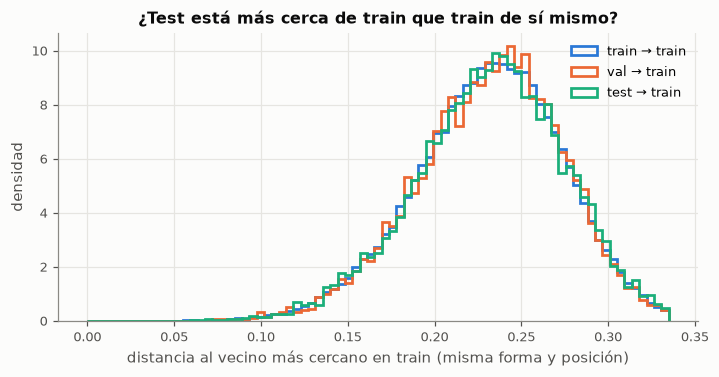

• [Fuga] distancia mediana al vecino de train: test 0.2338, val 0.2344, train→train 0.2334 (KS test vs train: D=0.011; val vs train: D=0.012). No hay escenas casi duplicadas: test y val son tan lejanos a train como train de sí mismo.


In [ ]:
def embed(df):
    cols = []
    for c in CONT:
        v = df[c].to_numpy(float)
        if c in HUES:
            cols += [np.cos(2 * np.pi * v) / (2 * np.pi), np.sin(2 * np.pi * v) / (2 * np.pi)]
        else:
            cols.append(v)
    # forma y posición con un desplazamiento enorme: el vecino siempre es de la misma combinación
    cols += [df["shape"].to_numpy(float) * 100, df["pos"].to_numpy(float) * 100]
    return np.column_stack(cols)


E = {s: embed(D[s]) for s in SPLITS}
tree = cKDTree(E["train"])
nn = {"train → train": tree.query(E["train"], k=2)[0][:, 1]}  # excluye la propia escena
for s in ("val", "test"):
    nn[f"{s} → train"] = tree.query(E[s], k=1)[0]

nn_tab = pd.DataFrame(
    {
        k: {
            "mínimo": v.min(),
            "p1": np.quantile(v, 0.01),
            "p5": np.quantile(v, 0.05),
            "mediana": np.median(v),
            "media": v.mean(),
        }
        for k, v in nn.items()
    }
).T
display(nn_tab)
save_table(nn_tab, "02_vecino_mas_cercano")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
bins = np.linspace(0, np.quantile(np.concatenate(list(nn.values())), 0.995), 80)
for (k, v), col in zip(nn.items(), SPLIT_COLORS.values()):
    ax.hist(v, bins=bins, density=True, histtype="step", lw=1.8, color=col, label=k)
ax.set_xlabel("distancia al vecino más cercano en train (misma forma y posición)")
ax.set_ylabel("densidad")
ax.set_title("¿Test está más cerca de train que train de sí mismo?")
ax.legend()
savefig(fig, "02_vecino_mas_cercano")
plt.show()

# Bajo i.i.d. la distancia al vecino escala como n^(-1/d): train→train (n−1 escenas) y test→train (n escenas)
# deberían tener casi la misma distribución.
ks_t = stats.ks_2samp(nn["test → train"], nn["train → train"])
ks_v = stats.ks_2samp(nn["val → train"], nn["train → train"])
note(
    "Fuga",
    f"distancia mediana al vecino de train: test {np.median(nn['test → train']):.4f}, "
    f"val {np.median(nn['val → train']):.4f}, train→train {np.median(nn['train → train']):.4f} "
    f"(KS test vs train: D={ks_t.statistic:.3f}; val vs train: D={ks_v.statistic:.3f}). "
    + (
        "No hay escenas casi duplicadas: test y val son tan lejanos a train como train de sí mismo."
        if max(ks_t.statistic, ks_v.statistic) < 0.05
        else "Revisar: las distribuciones difieren."
    ),
)

### 2.1 Captions repetidos entre splits

Las escenas son distintas, pero el **texto** no: un caption de M3DI depende solo de forma, posición, nombre de
color (~100) y plantilla (5), así que hay a lo sumo $7 \cdot 9 \cdot 100 \cdot 5 = 31\,500$ captions posibles.
Que un caption de test aparezca literalmente en train no es una fuga de imágenes, pero sí importa en dos
lugares:

* **VL-JEPA decodifica por recuperación** sobre un banco de captions de train (`bank.max_captions = 20 000` filas,
  semilla 0). Si el caption correcto no está en el banco, la recuperación no puede devolverlo: es un techo
  para las métricas de texto y para el "nombre exacto".
* **Un VLM ajustado** puede reproducir captions vistos sin generalizar.

In [ ]:
cap_train = set(D["train"]["caption"])
bank_idx = sorted(
    random.Random(BANK_SEED).sample(range(len(D["train"])), BANK_MAX_CAPTIONS)
)  # = load_manifest(limit, subset_seed)
bank = set(D["train"]["caption"].iloc[bank_idx])
canon_train = set(D["train"]["canonical"])

rows = []
for s in SPLITS:
    c, k = D[s]["caption"], D[s]["canonical"]
    rows.append(
        {
            "split": s,
            "captions únicos": c.nunique(),
            "únicos / filas": c.nunique() / len(c),
            "filas con caption en train": c.isin(cap_train).mean() if s != "train" else np.nan,
            "filas con caption en banco VL-JEPA": c.isin(bank).mean(),
            "canónicos únicos": k.nunique(),
            "filas con canónico en train": k.isin(canon_train).mean() if s != "train" else np.nan,
        }
    )
caps_tab = pd.DataFrame(rows).set_index("split")
display(caps_tab)
save_table(caps_tab, "02_captions_compartidos")
note(
    "Captions",
    f"captions únicos: train {len(cap_train):,}, val {D['val']['caption'].nunique():,}, "
    f"test {D['test']['caption'].nunique():,}; el {caps_tab.loc['test', 'filas con caption en train']:.1%} "
    "de las filas de test tiene un caption que aparece literal en train.",
)
note(
    "Captions",
    f"banco de VL-JEPA ({BANK_MAX_CAPTIONS:,} filas de train → {len(bank):,} captions únicos) contiene el caption "
    f"correcto en el {caps_tab.loc['test', 'filas con caption en banco VL-JEPA']:.1%} de test: techo de la "
    "recuperación exacta con el objetivo original. Con el canónico la cobertura es "
    f"{caps_tab.loc['test', 'filas con canónico en train']:.1%}.",
)

,captions únicos,únicos / filas,filas con caption en train,filas con caption en banco VL-JEPA,canónicos únicos,filas con canónico en train
split,,,,,,
train,10936,0.0875,NaN,0.8735,231,NaN
val,5372,0.5372,0.9943,0.8549,231,1.0
test,5385,0.5385,0.9943,0.8551,231,1.0


• [Captions] captions únicos: train 10,936, val 5,372, test 5,385; el 99.4% de las filas de test tiene un caption que aparece literal en train.
• [Captions] banco de VL-JEPA (20,000 filas de train → 7,492 captions únicos) contiene el caption correcto en el 85.5% de test: techo de la recuperación exacta con el objetivo original. Con el canónico la cobertura es 100.0%.


## 3. Latentes de imagen vs de texto

El caption se genera desde los latentes de texto. Si difieren de los de imagen, ningún modelo puede ser fiel a la
vez a la imagen y al caption: la tasa de desacuerdo acota la exactitud alcanzable por atributo.

In [ ]:
dis = pd.DataFrame(
    {s: {a: float((D[s][a] != D[s][f"t_{a}"]).mean()) for a in ("shape", "x", "y")} for s in SPLITS}
).T
dis.columns = ["forma", "x", "y"]
display(dis)
save_table(dis, "03_desacuerdo_imagen_texto")
note(
    "Imagen vs texto",
    "forma, x e y coinciden en el 100 % de las filas de los tres splits: el techo por atributo es 1."
    if dis.to_numpy().max() == 0
    else f"desacuerdo máximo {dis.to_numpy().max():.2%}.",
)

,forma,x,y
train,0.0,0.0,0.0
val,0.0,0.0,0.0
test,0.0,0.0,0.0


• [Imagen vs texto] forma, x e y coinciden en el 100 % de las filas de los tres splits: el techo por atributo es 1.


## 4. Atributos discretos por split

Para cada atributo se compara la distribución en los tres splits:

* **χ² de homogeneidad** sobre la tabla split × valor ($H_0$: misma distribución). Con $n = 145\,000$ detecta
  diferencias mínimas, así que se reporta también la **V de Cramér** (efecto; < 0,05 es despreciable).
* **Divergencia de Jensen–Shannon** train↔val y train↔test, en bits ($\in[0,1]$).
* $H/H_{\max}$: entropía normalizada, 1 = uniforme.

,K,H/Hmax train,min/max train,JSD train-val (bits),JSD train-test (bits),χ²,gl,p,V Cramér
atributo,,,,,,,,,
forma,7,1.0000,0.9789,6.7768e-05,1.3716e-05,4.1613,12,0.9803,0.0038
x,3,1.0000,0.9901,1.5512e-05,1.5621e-04,9.1609,4,0.0572,0.0056
y,3,1.0000,0.9903,2.3326e-05,4.9850e-05,3.8139,4,0.4318,0.0036
"celda (x,y)",9,1.0000,0.9696,1.7275e-04,2.8608e-04,24.5351,16,0.0785,0.0092
color básico,8,0.9503,0.2761,1.5771e-04,1.5575e-04,16.1587,14,0.3038,0.0075
plantilla,5,1.0000,0.9845,2.3286e-05,1.1853e-04,7.1933,8,0.5159,0.0050


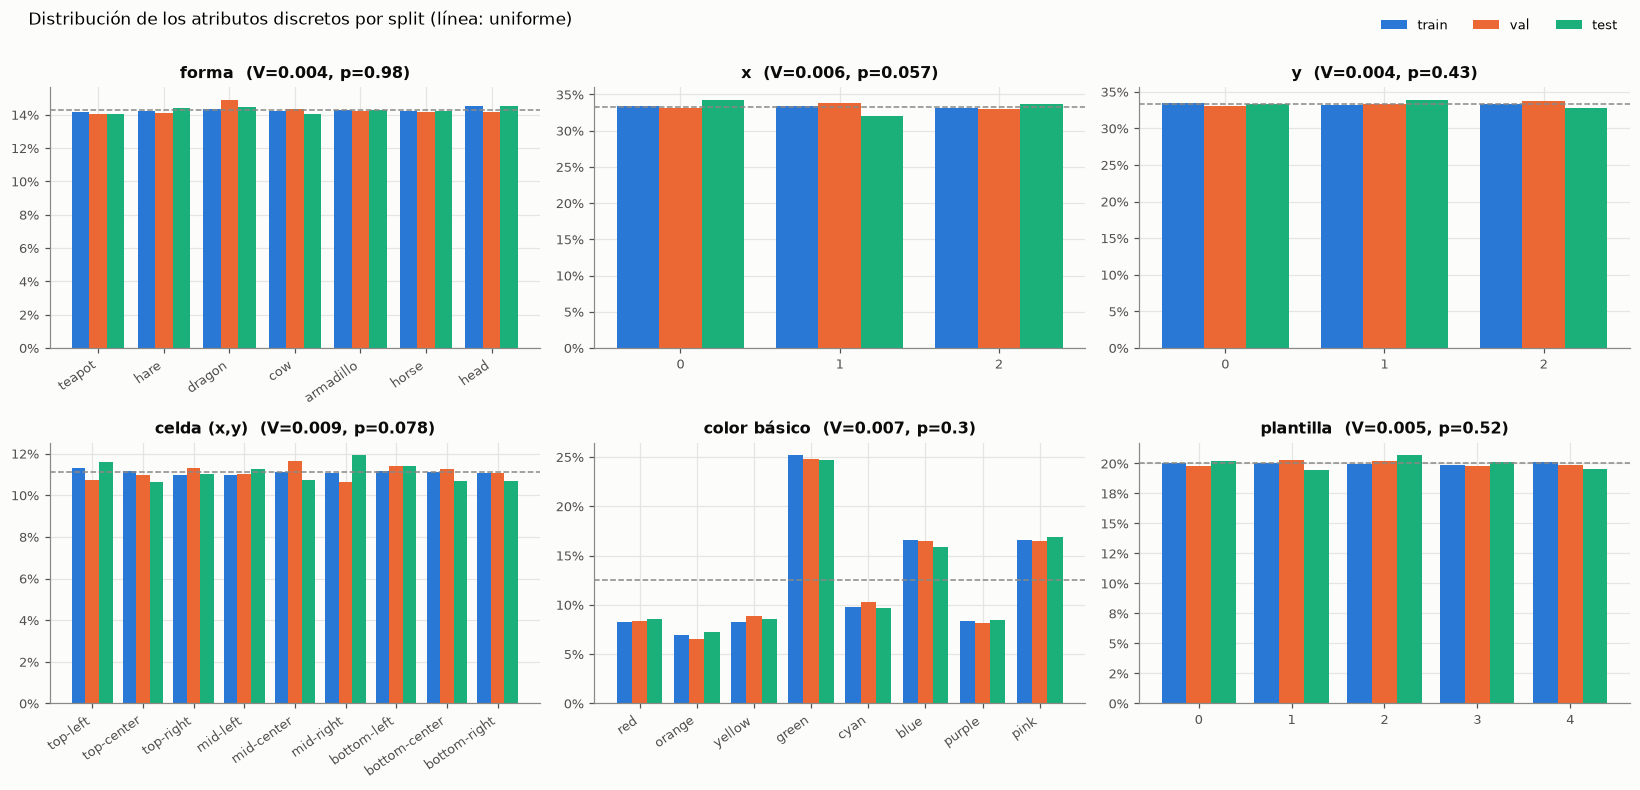

• [Discretos] los seis atributos discretos tienen la misma distribución en los tres splits: V de Cramér máx. 0.0092 (celda (x,y)), JSD máx. 2.86e-04 bits.
• [Discretos] en train: forma H/Hmax=1.000, x H/Hmax=1.000, y H/Hmax=1.000, celda (x,y) H/Hmax=1.000, color básico H/Hmax=0.950, plantilla H/Hmax=1.000. Forma, posición y plantilla son ~uniformes; el color básico no (las 8 categorías cubren arcos de matiz distintos).


In [ ]:
DISC = {
    "forma": ("shape_name", SHAPE_LABELS),
    "x": ("x", [0, 1, 2]),
    "y": ("y", [0, 1, 2]),
    "celda (x,y)": ("cell", POS_LABELS),
    "color básico": ("color_cat", COLOR_CATS),
    "plantilla": ("phrasing", sorted(D["train"]["phrasing"].unique())),
}
FREQ = {}
rows = []
for name, (col, levels) in DISC.items():
    tab = pd.DataFrame({s: D[s][col].value_counts().reindex(levels, fill_value=0) for s in SPLITS})
    FREQ[name] = tab
    chi2, p, dof, v = homogeneity(tab.T.to_numpy())
    pr = tab / tab.sum()
    rows.append(
        {
            "atributo": name,
            "K": len(levels),
            "H/Hmax train": entropy_bits(D["train"][col]) / math.log2(len(levels)),
            "min/max train": tab["train"].min() / tab["train"].max(),
            "JSD train-val (bits)": jsd_bits(pr["train"], pr["val"]),
            "JSD train-test (bits)": jsd_bits(pr["train"], pr["test"]),
            "χ²": chi2,
            "gl": dof,
            "p": p,
            "V Cramér": v,
        }
    )
disc_tab = pd.DataFrame(rows).set_index("atributo")
display(disc_tab)
save_table(disc_tab, "04_homogeneidad_discretos")

fig, axes = plt.subplots(2, 3, figsize=(15, 7.2))
for ax, (name, tab) in zip(axes.flat, FREQ.items()):
    pr = tab / tab.sum()
    k = len(pr)
    w = 0.8 / 3
    for j, s in enumerate(SPLITS):
        ax.bar(np.arange(k) + (j - 1) * w, pr[s], width=w, color=SPLIT_COLORS[s], label=s)
    ax.axhline(1 / k, color=INK3, ls="--", lw=1)
    ax.set_xticks(
        range(k),
        [str(l) for l in pr.index],
        rotation=35 if k > 5 else 0,
        ha="right" if k > 5 else "center",
    )
    ax.yaxis.set_major_formatter(PCT)
    r = disc_tab.loc[name]
    ax.set_title(f"{name}  (V={r['V Cramér']:.3f}, p={r['p']:.2g})")
fig.tight_layout(rect=(0, 0, 1, 0.94))
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, ncol=3, loc="upper right", bbox_to_anchor=(0.99, 0.995))
fig.suptitle(
    "Distribución de los atributos discretos por split (línea: uniforme)", x=0.02, y=0.99, ha="left"
)
savefig(fig, "04_discretos_por_split")
plt.show()

worst = disc_tab["V Cramér"].idxmax()
note(
    "Discretos",
    f"los seis atributos discretos tienen la misma distribución en los tres splits: V de Cramér máx. "
    f"{disc_tab['V Cramér'].max():.4f} ({worst}), JSD máx. "
    f"{disc_tab[['JSD train-val (bits)', 'JSD train-test (bits)']].to_numpy().max():.2e} bits.",
)
unif = disc_tab["H/Hmax train"]
note(
    "Discretos",
    "en train: "
    + ", ".join(f"{k} H/Hmax={v:.3f}" for k, v in unif.items())
    + ". Forma, posición y plantilla son ~uniformes; el color básico no (las 8 categorías cubren arcos de matiz distintos).",
)

### 4.1 El color básico no es uniforme: arcos de matiz

`object_color` es un matiz uniforme en $[0,1)$, pero `hue_to_cat` lo corta en arcos de distinto ancho
(`HUE_UPPER`). La probabilidad de cada categoría es simplemente el ancho de su arco / 360°: no es un sesgo del
muestreo, es la definición de las categorías. Esto fija la exactitud de azar del color (§10).

,ancho del arco (esperado),train,val,test
red,0.0833,0.0830,0.0837,0.0857
orange,0.0694,0.0696,0.0656,0.0729
yellow,0.0833,0.0826,0.0882,0.0859
green,0.2500,0.2519,0.2479,0.2472
cyan,0.0972,0.0982,0.1024,0.0965
blue,0.1667,0.1659,0.1652,0.1589
purple,0.0833,0.0834,0.0820,0.0843
pink,0.1667,0.1654,0.1650,0.1686


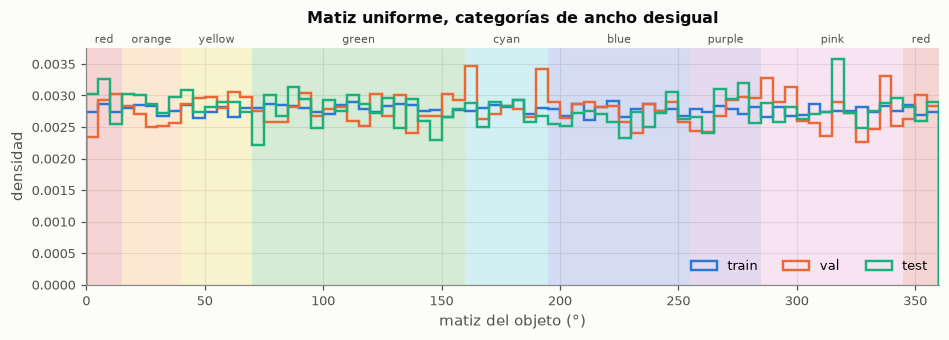

• [Color] la frecuencia de cada categoría básica coincide con el ancho de su arco de matiz (desvío máx. 0.0019); va de 6.9% (orange) a 25.0% (green).


In [ ]:
edges = [0] + HUE_UPPER + [360]
cats = COLOR_CATS + ["red"]  # el último arco (345°–360°) vuelve a ser rojo
width = {c: 0.0 for c in COLOR_CATS}
for c, lo, hi in zip(cats, edges[:-1], edges[1:]):
    width[c] += (hi - lo) / 360
exp_vs_obs = pd.DataFrame({"ancho del arco (esperado)": pd.Series(width)})
for s in SPLITS:
    exp_vs_obs[s] = FREQ["color básico"][s] / FREQ["color básico"][s].sum()
display(exp_vs_obs)
save_table(exp_vs_obs, "04_color_arcos")

fig, ax = plt.subplots(figsize=(10, 2.8))
h = np.concatenate([D[s]["hue_obj"].to_numpy() for s in SPLITS]) * 360
for c, lo, hi in zip(cats, edges[:-1], edges[1:]):
    ax.axvspan(lo, hi, color=CAT_COLORS[c], alpha=0.18, lw=0)
    ax.text(
        (lo + hi) / 2,
        1.02,
        c,
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=7.5,
        color=INK2,
    )
for s in SPLITS:
    ax.hist(
        D[s]["hue_obj"] * 360,
        bins=72,
        range=(0, 360),
        density=True,
        histtype="step",
        lw=1.6,
        color=SPLIT_COLORS[s],
        label=s,
    )
ax.set_xlim(0, 360)
ax.set_xlabel("matiz del objeto (°)")
ax.set_ylabel("densidad")
ax.legend(loc="lower right", ncol=3)
ax.set_title("Matiz uniforme, categorías de ancho desigual", pad=16)
savefig(fig, "04_matiz_categorias")
plt.show()
mx = (exp_vs_obs["train"] - exp_vs_obs["ancho del arco (esperado)"]).abs().max()
note(
    "Color",
    f"la frecuencia de cada categoría básica coincide con el ancho de su arco de matiz (desvío máx. {mx:.4f}); "
    f"va de {min(width.values()):.1%} ({min(width, key=width.get)}) a {max(width.values()):.1%} ({max(width, key=width.get)}).",
)

## 5. Combinaciones forma × posición (63) y split composicional

El ajuste fino puede memorizar pares (forma, celda). El experimento composicional (`data.holdout: compositional`)
retira de train 14 de las 63 combinaciones (`HELD_OUT_COMBOS`, recuadros rojos) y las mide aparte en val y test.
Aquí se verifica que todas las combinaciones estén bien representadas en los tres splits y cuántos ejemplos
quedan en cada grupo.

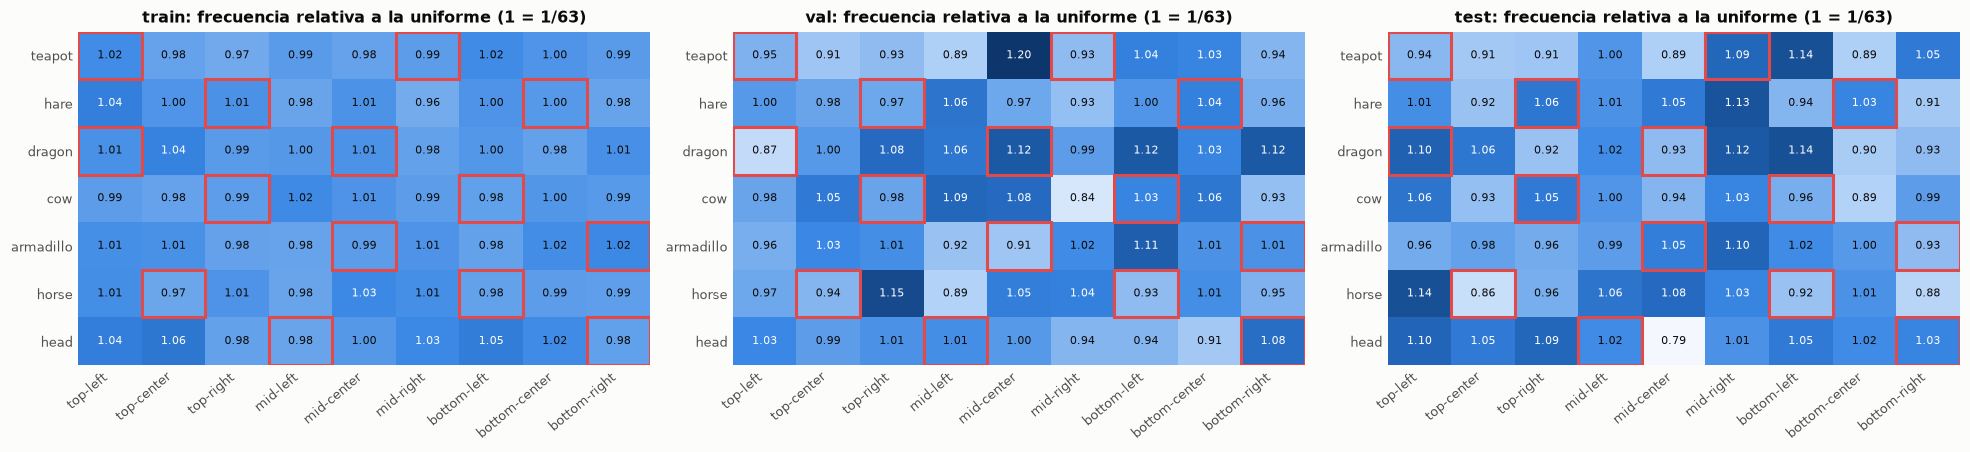

,mín. por combinación,máx.,esperado,χ² uniforme p,filas en combinaciones retiradas,fracción retirada
split,,,,,,
train,1912.0,2099.0,1984.1270,0.7657,27643.0,0.2211
val,134.0,190.0,158.7302,0.8546,2188.0,0.2188
test,126.0,181.0,158.7302,0.5327,2219.0,0.2219
train (holdout aplicado),1912.0,2099.0,NaN,NaN,0.0,0.0000


• [Composicional] las 63 combinaciones están presentes en los tres splits (mín. train 1,912, val 134, test 126); con el holdout, train pierde 27,643 filas (22.1%, quedan 97,357) y test evalúa 2,219 imágenes de combinaciones no vistas.
• [Composicional] cada forma pierde 2 celdas y cada celda se retira para top-left: 2, top-center: 1, top-right: 2, mid-left: 1, mid-center: 2, mid-right: 1, bottom-left: 2, bottom-center: 1, bottom-right: 2 formas: ninguna forma ni celda desaparece de train.


In [ ]:
def combo_counts(df):
    M = np.zeros((7, 9), int)
    np.add.at(M, (df["shape"].to_numpy(), df["pos"].to_numpy()), 1)
    return M


CC = {s: combo_counts(D[s]) for s in SPLITS}
held = np.zeros((7, 9), bool)
for sh, p in HELD_OUT_COMBOS:
    held[sh, p] = True

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, s in zip(axes, SPLITS):
    heat(
        ax,
        CC[s] / CC[s].sum() * 63,
        POS_LABELS,
        SHAPE_LABELS,
        fmt="{:.2f}",
        vmin=0.8,
        vmax=1.2,
        marks=held,
        fontsize=7,
    )
    ax.set_xticklabels(POS_LABELS, rotation=40, ha="right")
    ax.set_title(f"{s}: frecuencia relativa a la uniforme (1 = 1/63)")
fig.tight_layout()
savefig(fig, "05_combinaciones_forma_posicion")
plt.show()

rows = []
for s in SPLITS:
    M = CC[s]
    chi2, p = stats.chisquare(M.ravel())
    rows.append(
        {
            "split": s,
            "mín. por combinación": M.min(),
            "máx.": M.max(),
            "esperado": M.sum() / 63,
            "χ² uniforme p": p,
            "filas en combinaciones retiradas": int(M[held].sum()),
            "fracción retirada": M[held].sum() / M.sum(),
        }
    )
combo_tab = pd.DataFrame(rows).set_index("split")
combo_tab.loc["train (holdout aplicado)"] = [
    CC["train"][~held].min(),
    CC["train"][~held].max(),
    np.nan,
    np.nan,
    0,
    0.0,
]
display(combo_tab)
save_table(combo_tab, "05_combinaciones")

per_cell = held.sum(0)
note(
    "Composicional",
    f"las 63 combinaciones están presentes en los tres splits (mín. train {CC['train'].min():,}, "
    f"val {CC['val'].min()}, test {CC['test'].min()}); con el holdout, train pierde "
    f"{int(CC['train'][held].sum()):,} filas "
    f"({CC['train'][held].sum() / CC['train'].sum():.1%}, quedan {int(CC['train'][~held].sum()):,}) y test evalúa "
    f"{int(CC['test'][held].sum()):,} imágenes de combinaciones no vistas.",
)
note(
    "Composicional",
    "cada forma pierde 2 celdas y cada celda se retira para "
    + ", ".join(f"{POS_LABELS[p]}: {per_cell[p]}" for p in range(9))
    + " formas: ninguna forma ni celda desaparece de train.",
)

## 6. Latentes continuos (no descritos en el caption)

Rotaciones, matiz y posición del foco y matiz del fondo no aparecen en el texto, pero cambian la imagen (un fondo
del mismo matiz que el objeto lo camufla). Se compara cada uno entre splits con KS de dos muestras y contra la
uniforme en $[0,1]$.

,KS uniforme D (train),KS train-val D,KS train-val p,KS train-test D,KS train-test p
latente,,,,,
rot_alpha,0.0026,0.0098,0.3398,0.0075,0.6662
rot_beta,0.0017,0.0085,0.5089,0.0101,0.2945
rot_gamma,0.0017,0.0069,0.7606,0.0134,0.0713
hue_obj,0.0027,0.0063,0.8526,0.0102,0.2854
hue_spot,0.0017,0.0085,0.5132,0.0066,0.8167
pos_spot,0.0029,0.0125,0.1094,0.0071,0.7362
hue_bg,0.0031,0.0085,0.5077,0.0148,0.0338


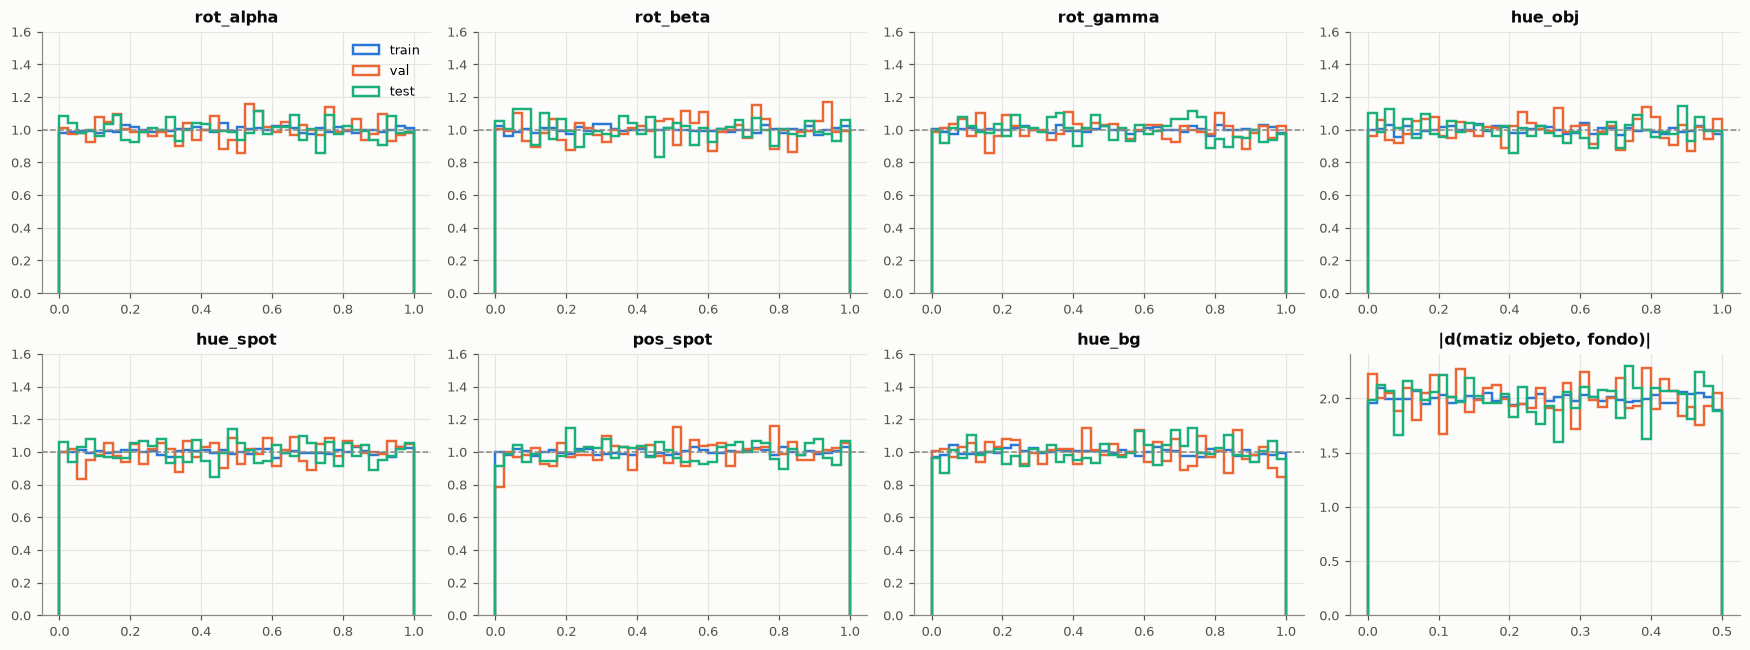

• [Continuos] los 7 latentes continuos son ~uniformes en [0,1] y homogéneos entre splits (KS train-val/test D máx. 0.0148).
• [Continuos] objeto y fondo con matiz a menos de 18° (camuflaje): train 10.1%, val 10.2%, test 9.8% — lo esperado bajo independencia (10 %).


In [ ]:
rows = []
for c in CONT:
    tr = D["train"][c].to_numpy()
    r = {"latente": c, "KS uniforme D (train)": stats.kstest(tr, "uniform").statistic}
    for s in ("val", "test"):
        k = stats.ks_2samp(tr, D[s][c].to_numpy())
        r[f"KS train-{s} D"], r[f"KS train-{s} p"] = k.statistic, k.pvalue
    rows.append(r)
cont_tab = pd.DataFrame(rows).set_index("latente")
display(cont_tab)
save_table(cont_tab, "06_latentes_continuos")

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.flat, CONT):
    for s in SPLITS:
        ax.hist(
            D[s][c],
            bins=40,
            range=(0, 1),
            density=True,
            histtype="step",
            lw=1.6,
            color=SPLIT_COLORS[s],
            label=s,
        )
    ax.axhline(1, color=INK3, ls="--", lw=1)
    ax.set_ylim(0, 1.6)
    ax.set_title(c)

# 8.º panel: contraste objeto–fondo en matiz, el factor "camuflaje"
ax = axes.flat[-1]
for s in SPLITS:
    d_bg = np.abs((D[s]["hue_obj"] - D[s]["hue_bg"] + 0.5) % 1 - 0.5)
    ax.hist(
        d_bg,
        bins=40,
        range=(0, 0.5),
        density=True,
        histtype="step",
        lw=1.6,
        color=SPLIT_COLORS[s],
        label=s,
    )
ax.set_title("|d(matiz objeto, fondo)|")
axes.flat[0].legend()
fig.tight_layout()
savefig(fig, "06_latentes_continuos")
plt.show()

camo = {
    s: float((np.abs((D[s]["hue_obj"] - D[s]["hue_bg"] + 0.5) % 1 - 0.5) < 0.05).mean())
    for s in SPLITS
}
note(
    "Continuos",
    f"los 7 latentes continuos son ~uniformes en [0,1] y homogéneos entre splits "
    f"(KS train-val/test D máx. {cont_tab[['KS train-val D', 'KS train-test D']].to_numpy().max():.4f}).",
)
note(
    "Continuos",
    "objeto y fondo con matiz a menos de 18° (camuflaje): "
    + ", ".join(f"{s} {v:.1%}" for s, v in camo.items())
    + " — lo esperado bajo independencia (10 %).",
)

## 7. Nombre de color, matiz y categoría básica

El caption original cita un **nombre** de color (`xkcd:fire engine red`, ~100 nombres) elegido a partir del matiz.
La métrica "color" compara la **categoría básica** del matiz (8), y "nombre" exige el nombre exacto. Preguntas:
¿el vocabulario de nombres es el mismo en los tres splits? ¿Cuántos nombres comparte cada categoría? ¿El nombre
determina la categoría?

,nombres distintos,nombres ausentes en train,filas con nombre ausente en train,H(nombre) bits,nombre más frecuente,frac. más frecuente
split,,,,,,
train,100,0,0.0,5.9614,tab:cyan,0.0606
val,99,0,0.0,5.9578,tab:cyan,0.0606
test,99,0,0.0,5.9544,tab:cyan,0.0579


<positron-console-cell-13>:18: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
<positron-console-cell-13>:18: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
<positron-console-cell-13>:19: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.


,nombres (mayoría en la categoría),P(nombre más frecuente | categoría),H(nombre | categoría) bits
color_cat,,,
red,9,0.3310,2.9512
orange,9,0.3202,3.0195
yellow,10,0.2484,3.2573
green,29,0.1785,4.2862
cyan,11,0.3339,2.9580
blue,11,0.2530,3.3882
purple,7,0.3214,2.6460
pink,14,0.1941,3.5532


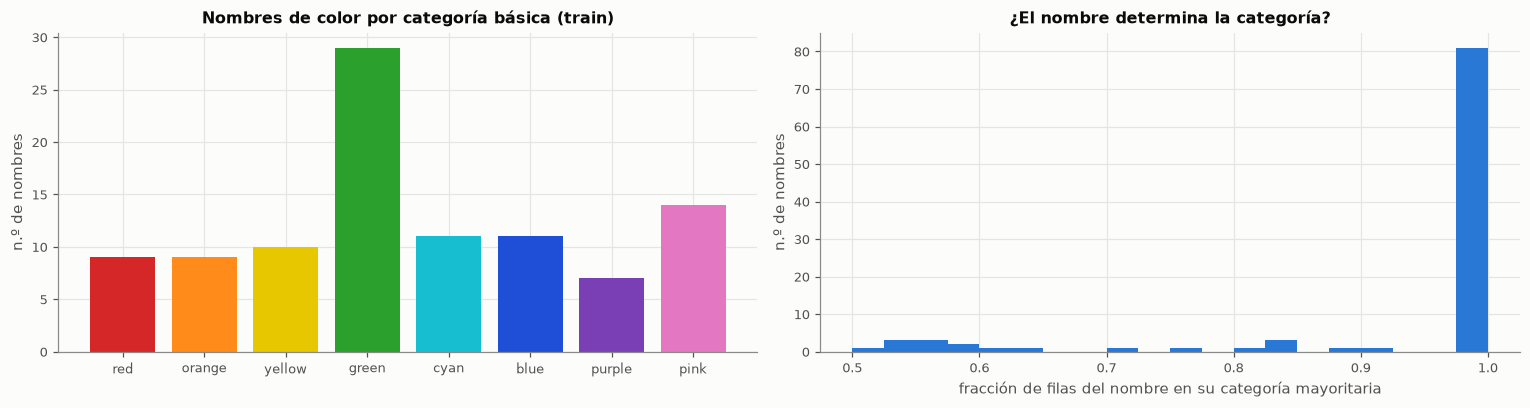

• [Color] vocabulario de nombres: train 100, val 99, test 99; nombres de val/test ausentes en train: 0.
• [Color] H(nombre)=5.96 bits vs H(categoría)=2.85 bits; I(nombre; categoría)=2.50 bits → conociendo la categoría quedan 3.46 bits de incertidumbre sobre el nombre. 78% de los nombres caen siempre en una sola categoría.


In [ ]:
names = {s: Counter(D[s]["color_name"]) for s in SPLITS}
vocab_tr = set(names["train"])
rows = []
for s in SPLITS:
    rows.append(
        {
            "split": s,
            "nombres distintos": len(names[s]),
            "nombres ausentes en train": len(set(names[s]) - vocab_tr),
            "filas con nombre ausente en train": sum(
                v for k, v in names[s].items() if k not in vocab_tr
            )
            / len(D[s]),
            "H(nombre) bits": entropy_bits(D[s]["color_name"]),
            "nombre más frecuente": names[s].most_common(1)[0][0],
            "frac. más frecuente": names[s].most_common(1)[0][1] / len(D[s]),
        }
    )
names_tab = pd.DataFrame(rows).set_index("split")
display(names_tab)
save_table(names_tab, "07_nombres_color")

# nombre ↔ categoría básica (train)
tr = D["train"]
name_cat = pd.crosstab(tr["color_name"], tr["color_cat"])
purity = name_cat.max(1) / name_cat.sum(1)
n_per_cat = (name_cat.div(name_cat.sum(1), axis=0) >= 0.5).sum().reindex(COLOR_CATS)
p_name_given_cat = (
    tr.groupby("color_cat")["color_name"]
    .agg(lambda v: v.value_counts(normalize=True).max())
    .reindex(COLOR_CATS)
)
cat_tab = pd.DataFrame(
    {
        "nombres (mayoría en la categoría)": n_per_cat,
        "P(nombre más frecuente | categoría)": p_name_given_cat,
        "H(nombre | categoría) bits": tr.groupby("color_cat")["color_name"]
        .agg(entropy_bits)
        .reindex(COLOR_CATS),
    }
)
display(cat_tab)
save_table(cat_tab, "07_nombres_por_categoria")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
ax = axes[0]
ax.bar(
    COLOR_CATS,
    cat_tab["nombres (mayoría en la categoría)"],
    color=[CAT_COLORS[c] for c in COLOR_CATS],
)
ax.set_title("Nombres de color por categoría básica (train)")
ax.set_ylabel("n.º de nombres")
ax = axes[1]
ax.hist(purity, bins=20, range=(0.5, 1), color=SERIES[0])
ax.set_xlabel("fracción de filas del nombre en su categoría mayoritaria")
ax.set_ylabel("n.º de nombres")
ax.set_title("¿El nombre determina la categoría?")
fig.tight_layout()
savefig(fig, "07_nombres_categoria")
plt.show()

H_name, H_cat = entropy_bits(tr["color_name"]), entropy_bits(tr["color_cat"])
I_nc = mutual_info_bits(tr["color_name"], tr["color_cat"])
note(
    "Color",
    f"vocabulario de nombres: train {len(names['train'])}, val {len(names['val'])}, test {len(names['test'])}; "
    f"nombres de val/test ausentes en train: {names_tab['nombres ausentes en train'].iloc[1:].sum()}.",
)
note(
    "Color",
    f"H(nombre)={H_name:.2f} bits vs H(categoría)={H_cat:.2f} bits; I(nombre; categoría)={I_nc:.2f} bits → "
    f"conociendo la categoría quedan {H_name - I_nc:.2f} bits de incertidumbre sobre el nombre. "
    f"{(purity == 1).mean():.0%} de los nombres caen siempre en una sola categoría.",
)

## 8. Captions: plantillas, longitud y textos distintos

El caption original tiene 5 plantillas elegidas al azar (ruido que no depende de la imagen); el objetivo
canónico de la etapa 2 usa una sola. Se compara longitud y vocabulario por split, y cuántas filas comparte cada
texto: eso es lo que ve el banco de negativos de VL-JEPA (`objective.negatives: bank`).

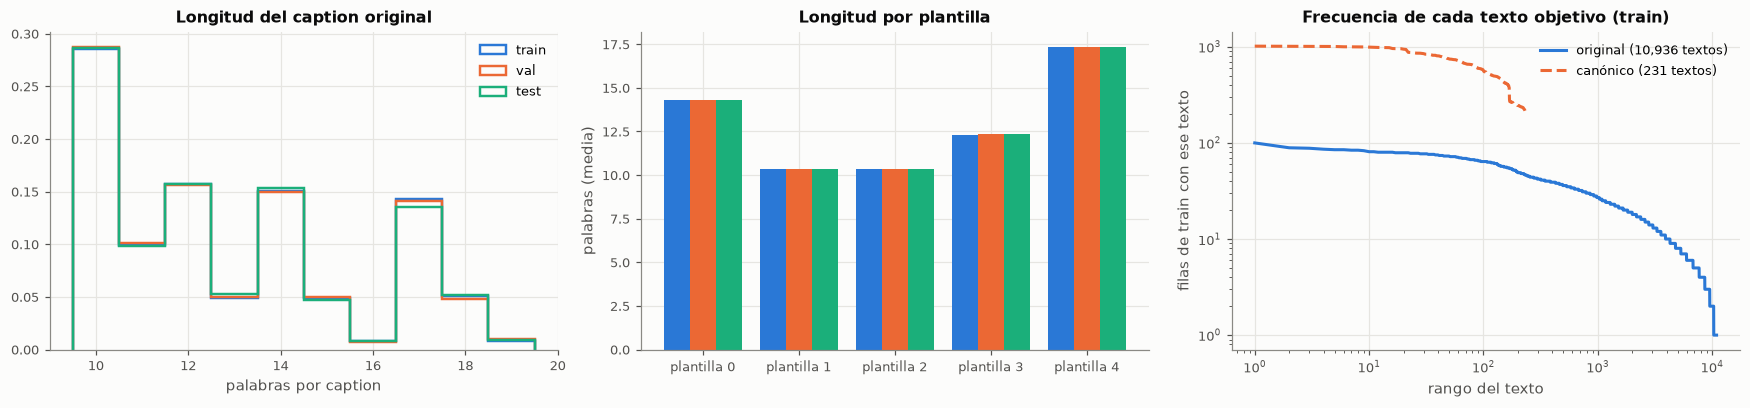

,train,val,test,ejemplo (train)
phrasing,,,,
0,14.3242,14.3205,14.3155,"A head of ""tab:olive"" color is visible, positi..."
1,10.3290,10.3251,10.3273,"A ""tab:blue"" horse is at the bottom-right of t..."
2,10.3220,10.3375,10.3256,"The mid-center of the image shows a ""xkcd:brig..."
3,12.3212,12.3369,12.3333,At the bottom-right of the picture is a hare i...
4,17.3304,17.3375,17.3529,"At the bottom-left of the image, there is a ""x..."


• [Captions] longitud media: train 12.93, val 12.91, test 12.91 palabras (rango 10–19); vocabulario: train 114, val 114, test 114; palabras de test ausentes en train: 0.
• [Captions] objetivo canónico: 231 textos distintos en train (no 7·9·8 = 504: ver §9.1), con 216–1016 filas cada uno; el original: 10,936 textos, 6% de ellos vistos una sola vez.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ax = axes[0]
lens = np.arange(D["train"]["n_words"].min(), D["train"]["n_words"].max() + 2)
for s in SPLITS:
    ax.hist(
        D[s]["n_words"],
        bins=lens - 0.5,
        density=True,
        histtype="step",
        lw=1.6,
        color=SPLIT_COLORS[s],
        label=s,
    )
ax.set_xlabel("palabras por caption")
ax.set_title("Longitud del caption original")
ax.legend()

ax = axes[1]
for j, s in enumerate(SPLITS):
    g = D[s].groupby("phrasing")["n_words"].mean()
    ax.bar(np.arange(len(g)) + (j - 1) * 0.27, g, width=0.27, color=SPLIT_COLORS[s], label=s)
ax.set_xticks(range(len(g)), [f"plantilla {i}" for i in g.index])
ax.set_ylabel("palabras (media)")
ax.set_title("Longitud por plantilla")

ax = axes[2]
for s, ls in zip(("caption", "canonical"), ("-", "--")):
    v = D["train"][s].value_counts().to_numpy()
    ax.plot(
        np.arange(1, len(v) + 1),
        v,
        ls=ls,
        color=SERIES[0] if s == "caption" else SERIES[1],
        label=f"{'original' if s == 'caption' else 'canónico'} ({len(v):,} textos)",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("rango del texto")
ax.set_ylabel("filas de train con ese texto")
ax.set_title("Frecuencia de cada texto objetivo (train)")
ax.legend()
fig.tight_layout()
savefig(fig, "08_captions")
plt.show()

tpl = pd.DataFrame(
    {
        s: D[s]
        .groupby("phrasing")
        .agg(n=("caption", "size"), palabras=("n_words", "mean"))["palabras"]
        for s in SPLITS
    }
)
tpl["ejemplo (train)"] = D["train"].groupby("phrasing")["caption"].first()
display(tpl)
save_table(tpl, "08_plantillas")

tok = lambda s: set(
    w.strip('.,"').lower() for c in D[s]["caption"] for w in c.replace('"', ' " ').split()
)
voc = {s: tok(s) for s in SPLITS}
vc_tr = D["train"]["canonical"].value_counts()
note(
    "Captions",
    f"longitud media: "
    + ", ".join(f"{s} {D[s]['n_words'].mean():.2f}" for s in SPLITS)
    + f" palabras (rango {D['train']['n_words'].min()}–{D['train']['n_words'].max()}); vocabulario: "
    + ", ".join(f"{s} {len(voc[s])}" for s in SPLITS)
    + f"; palabras de test ausentes en train: {len(voc['test'] - voc['train'])}.",
)
note(
    "Captions",
    f"objetivo canónico: {vc_tr.size} textos distintos en train (no 7·9·8 = 504: ver §9.1), "
    f"con {vc_tr.min()}–{vc_tr.max()} filas cada uno; el original: {D['train']['caption'].nunique():,} textos, "
    f"{(D['train']['caption'].value_counts() == 1).mean():.0%} de ellos vistos una sola vez.",
)

## 9. Dependencias entre atributos (atajos)

Información mutua normalizada $\mathrm{NMI}(A;B) = I(A;B)/\min\{H(A),H(B)\}$ entre los factores, en cada split.
Bajo independencia, $G = 2n\ln 2 \cdot \hat I \sim \chi^2_{(K_A-1)(K_B-1)}$. Una dependencia significativa sería un
atajo (acertar un atributo mirando otro). El sesgo del estimador es $\approx (K_A-1)(K_B-1)/(2n\ln 2)$ bits,
por lo que en val/test ($n=10^4$) la NMI de base no es exactamente 0.

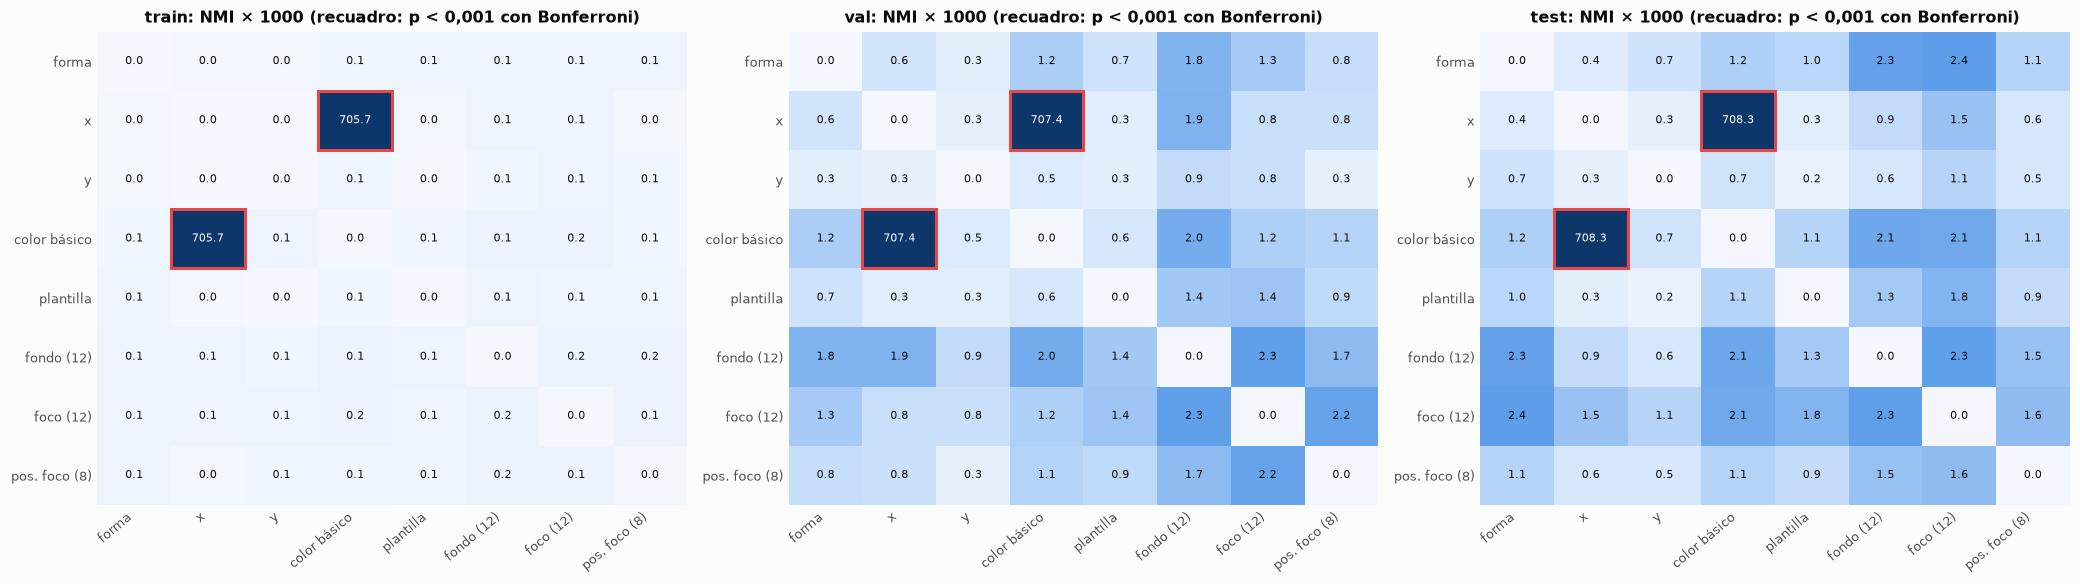

• [Dependencias] pares con dependencia significativa (G-test, Bonferroni α=0,001): train: x–color básico (NMI 0.706); val: x–color básico (NMI 0.707); test: x–color básico (NMI 0.708). Todos los demás pares tienen NMI < 0.0024 (independientes).


In [ ]:
def hue_bins(h, k=12):
    return np.floor(np.asarray(h) * k).astype(int) % k


FACT = {
    "forma": lambda d: d["shape"].to_numpy(),
    "x": lambda d: d["x"].to_numpy(),
    "y": lambda d: d["y"].to_numpy(),
    "color básico": lambda d: d["color_cat"].to_numpy(),
    "plantilla": lambda d: d["phrasing"].to_numpy(),
    "fondo (12)": lambda d: hue_bins(d["hue_bg"]),
    "foco (12)": lambda d: hue_bins(d["hue_spot"]),
    "pos. foco (8)": lambda d: np.minimum((d["pos_spot"].to_numpy() * 8).astype(int), 7),
}
keys = list(FACT)
NMI, PV = {}, {}
for s in SPLITS:
    V = {k: f(D[s]) for k, f in FACT.items()}
    n = len(D[s])
    M, P = np.full((len(keys),) * 2, np.nan), np.full((len(keys),) * 2, np.nan)
    for i, a in enumerate(keys):
        for j, b in enumerate(keys):
            if i == j:
                continue
            I = mutual_info_bits(V[a], V[b])
            M[i, j] = I / min(entropy_bits(V[a]), entropy_bits(V[b]))
            dof = (len(np.unique(V[a])) - 1) * (len(np.unique(V[b])) - 1)
            P[i, j] = stats.chi2.sf(2 * n * math.log(2) * I, dof)
    NMI[s], PV[s] = M, P

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))
for ax, s in zip(axes, SPLITS):
    heat(
        ax,
        np.nan_to_num(NMI[s]) * 1000,
        keys,
        keys,
        fmt="{:.1f}",
        vmin=0,
        vmax=5,
        fontsize=7,
        marks=(PV[s] < 0.001 / (len(keys) * (len(keys) - 1) / 2)),
    )
    ax.set_xticklabels(keys, rotation=40, ha="right")
    ax.set_title(f"{s}: NMI × 1000 (recuadro: p < 0,001 con Bonferroni)")
fig.tight_layout()
savefig(fig, "09_dependencias")
plt.show()

alpha = 0.001 / (len(keys) * (len(keys) - 1) / 2)
sig = {
    s: [
        (keys[i], keys[j])
        for i in range(len(keys))
        for j in range(i + 1, len(keys))
        if PV[s][i, j] < alpha
    ]
    for s in SPLITS
}
i_x, i_c = keys.index("x"), keys.index("color básico")
note(
    "Dependencias",
    "pares con dependencia significativa (G-test, Bonferroni α=0,001): "
    + "; ".join(
        f"{s}: {', '.join(f'{a}–{b} (NMI {NMI[s][keys.index(a), keys.index(b)]:.3f})' for a, b in sig[s]) or 'ninguno'}"
        for s in SPLITS
    )
    + ". Todos los demás pares tienen NMI < "
    + f"{max(np.nanmax(np.where(PV[s] < alpha, np.nan, NMI[s])) for s in SPLITS):.4f} (independientes).",
)

### 9.1 El matiz del objeto depende de la posición horizontal

La única dependencia fuerte es **x ↔ color**, y es parte del diseño causal de Multimodal3DIdent: el matiz del
objeto se muestrea en un tercio del círculo según su posición horizontal. Consecuencias:

* **Atajo**: conocer el color restringe mucho la columna y viceversa. Un modelo puede acertar x "mirando" el
  color (o al revés), y la exactitud de x y de color no son evidencia independiente de percepción.
* **Textos canónicos**: solo existen los pares (x, categoría) compatibles, así que hay $7 \cdot 3 \cdot n_{(x,\text{color})}$
  captions canónicos en vez de $7 \cdot 9 \cdot 8 = 504$. Ese es el tamaño real del banco de negativos de VL-JEPA.
* **Líneas base condicionales**: la exactitud de azar de x **dado el color** (y del color dado x) es mucho mayor que
  la marginal de §10.

<positron-console-cell-16>:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.


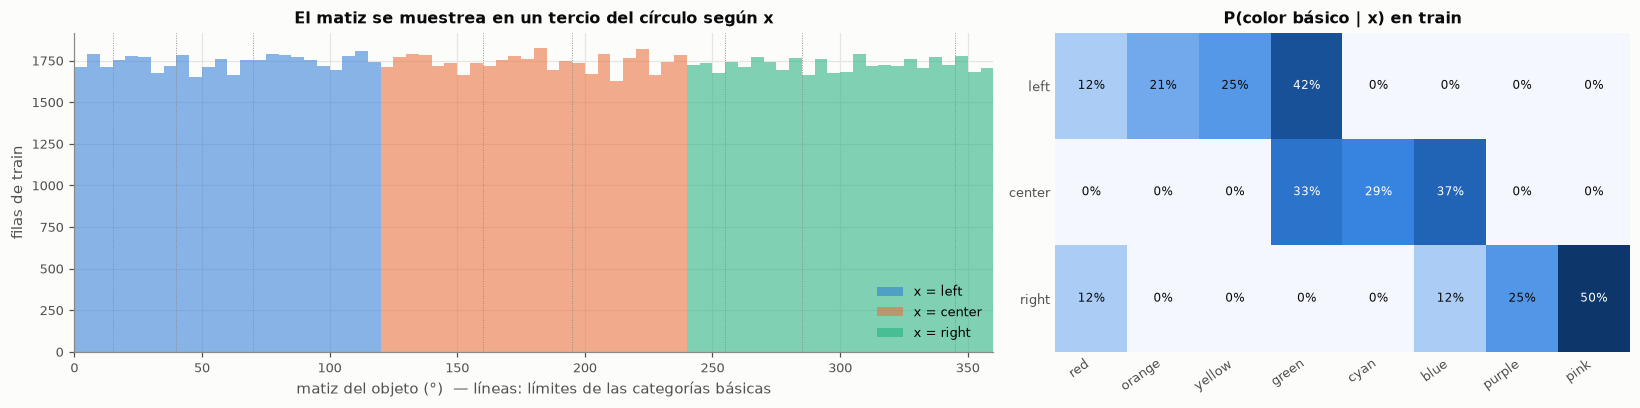

,min,max
x,,
left,5.2569e-06,0.3333
center,3.3333e-01,0.6667
right,6.6668e-01,1.0000


,train,val,test
x | color básico,0.8064,0.8045,0.8092
color básico | x,0.4309,0.4249,0.4255
x (marginal),0.3333,0.3333,0.3333
color básico (mayoritario),0.2519,0.2479,0.2472


• [Dependencias] el matiz del objeto está acotado por x: left [0.000, 0.333], center [0.333, 0.667], right [0.667, 1.000]. Solo 11 de 24 pares (x, color básico) existen → 231 captions canónicos posibles (no 504), lo que coincide con los 231 observados en train.
• [Dependencias] atajo: adivinar x a partir del color acierta 80.9% en test (vs 33,3 % sin información) y el color a partir de x 42.5% (vs 24.7% con la clase mayoritaria).


In [ ]:
tr = D["train"]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for xv in range(3):
    ax.hist(
        tr.loc[tr["x"] == xv, "hue_obj"] * 360,
        bins=72,
        range=(0, 360),
        histtype="stepfilled",
        alpha=0.55,
        color=SERIES[xv],
        label=f"x = {XPOS_NAMES[xv]}",
    )
for e in HUE_UPPER:
    ax.axvline(e, color=INK3, lw=0.6, ls=":")
ax.set_xlim(0, 360)
ax.set_xlabel("matiz del objeto (°)  — líneas: límites de las categorías básicas")
ax.set_ylabel("filas de train")
ax.set_title("El matiz se muestrea en un tercio del círculo según x")
ax.legend()

xc = pd.crosstab(tr["x"].map(XPOS_NAMES), tr["color_cat"]).reindex(
    index=list(XPOS_NAMES.values()), columns=COLOR_CATS
)
heat(
    axes[1],
    xc.div(xc.sum(1), axis=0).to_numpy(),
    COLOR_CATS,
    xc.index.tolist(),
    fmt="{:.0%}",
    vmin=0,
    vmax=0.5,
)
axes[1].set_xticklabels(COLOR_CATS, rotation=35, ha="right")
axes[1].set_title("P(color básico | x) en train")
fig.tight_layout()
savefig(fig, "09_matiz_vs_x")
plt.show()

ranges = tr.groupby("x")["hue_obj"].agg(["min", "max"]).rename(index=XPOS_NAMES)
display(ranges)
n_pairs = int((xc > 0).to_numpy().sum())


def cond_acc(target, given, df):
    # exactitud del mejor adivinador de `target` que solo conoce `given` (regla de Bayes ajustada en train)
    rule = tr.groupby(given)[target].agg(lambda v: v.value_counts().idxmax())
    return float((df[given].map(rule) == df[target]).mean())


cond = pd.DataFrame(
    {
        s: {
            "x | color básico": cond_acc("x", "color_cat", D[s]),
            "color básico | x": cond_acc("color_cat", "x", D[s]),
            "x (marginal)": 1 / 3,
            "color básico (mayoritario)": float(
                (D[s]["color_cat"] == tr["color_cat"].value_counts().idxmax()).mean()
            ),
        }
        for s in SPLITS
    }
)
display(cond)
save_table(cond, "09_bases_condicionales")
save_table(ranges, "09_rango_matiz_por_x")
note(
    "Dependencias",
    f"el matiz del objeto está acotado por x: "
    + ", ".join(f"{i} [{r['min']:.3f}, {r['max']:.3f}]" for i, r in ranges.iterrows())
    + f". Solo {n_pairs} de 24 pares (x, color básico) existen → {7 * 3 * n_pairs} captions canónicos posibles "
    f"(no 504), lo que coincide con los {tr['canonical'].nunique()} observados en train.",
)
note(
    "Dependencias",
    f"atajo: adivinar x a partir del color acierta {cond.loc['x | color básico', 'test']:.1%} en test "
    f"(vs 33,3 % sin información) y el color a partir de x {cond.loc['color básico | x', 'test']:.1%} "
    f"(vs {cond.loc['color básico (mayoritario)', 'test']:.1%} con la clase mayoritaria).",
)

## 10. Líneas base de azar

Dos adivinadores que no miran la imagen y solo conocen train:

* **mayoritario**: siempre dice la clase más frecuente en train;
* **marginal**: muestrea de la marginal de train; su exactitud esperada en un split es $\sum_k p^{\text{train}}_k\, p^{\text{split}}_k$.

Son las referencias para leer la exactitud zero-shot (p. ej. la de VL-JEPA en `vljepa_puntos_sobre_azar.csv`).
Para el nombre exacto y la posición conjunta las bases son muy bajas; para color ±1 (categoría correcta o vecina)
la base es alta, porque tres de ocho categorías ya cuentan como acierto.

In [ ]:
def color_adj_hit(pred, true):
    i, j = COLOR_CATS.index(pred), COLOR_CATS.index(true)
    d = abs(i - j)
    return min(d, 8 - d) <= 1


BASE = {
    "forma": "shape_name",
    "x": "x",
    "y": "y",
    "posición (x,y)": "cell",
    "color": "color_cat",
    "nombre exacto": "color_name",
}
pt = {k: D["train"][c].value_counts(normalize=True) for k, c in BASE.items()}
rows = []
for s in SPLITS:
    r = {"split": s}
    for k, c in BASE.items():
        ps = D[s][c].value_counts(normalize=True)
        r[f"{k} · mayoritario"] = float((D[s][c] == pt[k].idxmax()).mean())
        r[f"{k} · marginal"] = float((pt[k] * ps.reindex(pt[k].index, fill_value=0)).sum())
    # color ±1: probabilidad de caer en la categoría o una vecina con el adivinador marginal
    pc, ps = pt["color"], D[s]["color_cat"].value_counts(normalize=True)
    r["color ±1 · marginal"] = float(
        sum(pc[a] * ps.get(b, 0) for a in pc.index for b in ps.index if color_adj_hit(a, b))
    )
    r["color ±1 · mayoritario"] = float(
        np.mean([color_adj_hit(pc.idxmax(), t) for t in D[s]["color_cat"]])
    )
    rows.append(r)
base = pd.DataFrame(rows).set_index("split").T
base.index = pd.MultiIndex.from_tuples(
    [tuple(i.split(" · ")) for i in base.index], names=["atributo", "adivinador"]
)
display(base)
save_table(base, "10_lineas_base")

bt = base["test"].unstack()
note(
    "Azar",
    "exactitud de azar en test (mayoritario / marginal de train): "
    + "; ".join(
        f"{a} {bt.loc[a, 'mayoritario']:.3f} / {bt.loc[a, 'marginal']:.3f}" for a in bt.index
    )
    + ".",
)

split                        train     val    test
atributo       adivinador                         
forma          mayoritario  0.1450  0.1414  0.1455
               marginal     0.1429  0.1429  0.1429
x              mayoritario  0.3345  0.3311  0.3429
               marginal     0.3333  0.3333  0.3333
y              mayoritario  0.3349  0.3299  0.3331
               marginal     0.3333  0.3333  0.3333
posición (x,y) mayoritario  0.1132  0.1071  0.1162
               marginal     0.1111  0.1111  0.1111
color          mayoritario  0.2519  0.2479  0.2472
               marginal     0.1535  0.1528  0.1523
nombre exacto  mayoritario  0.0606  0.0606  0.0579
               marginal     0.0231  0.0230  0.0230
color ±1       marginal     0.3829  0.3840  0.3820
               mayoritario  0.4327  0.4385  0.4296

• [Azar] exactitud de azar en test (mayoritario / marginal de train): color 0.247 / 0.152; color ±1 0.430 / 0.382; forma 0.145 / 0.143; nombre exacto 0.058 / 0.023; posición (x,y) 0.116 / 0.111; x 0.343 / 0.333; y 0.333 / 0.333.


## 11. Inspección visual

Una fila por split con escenas al azar, el caption original y el canónico. Si las imágenes no están en disco
(`data/raw/m3di/<split>/images`, ver `data/README.md`), la sección se omite.

findfont: Failed to find font weight semibold, now using 700.


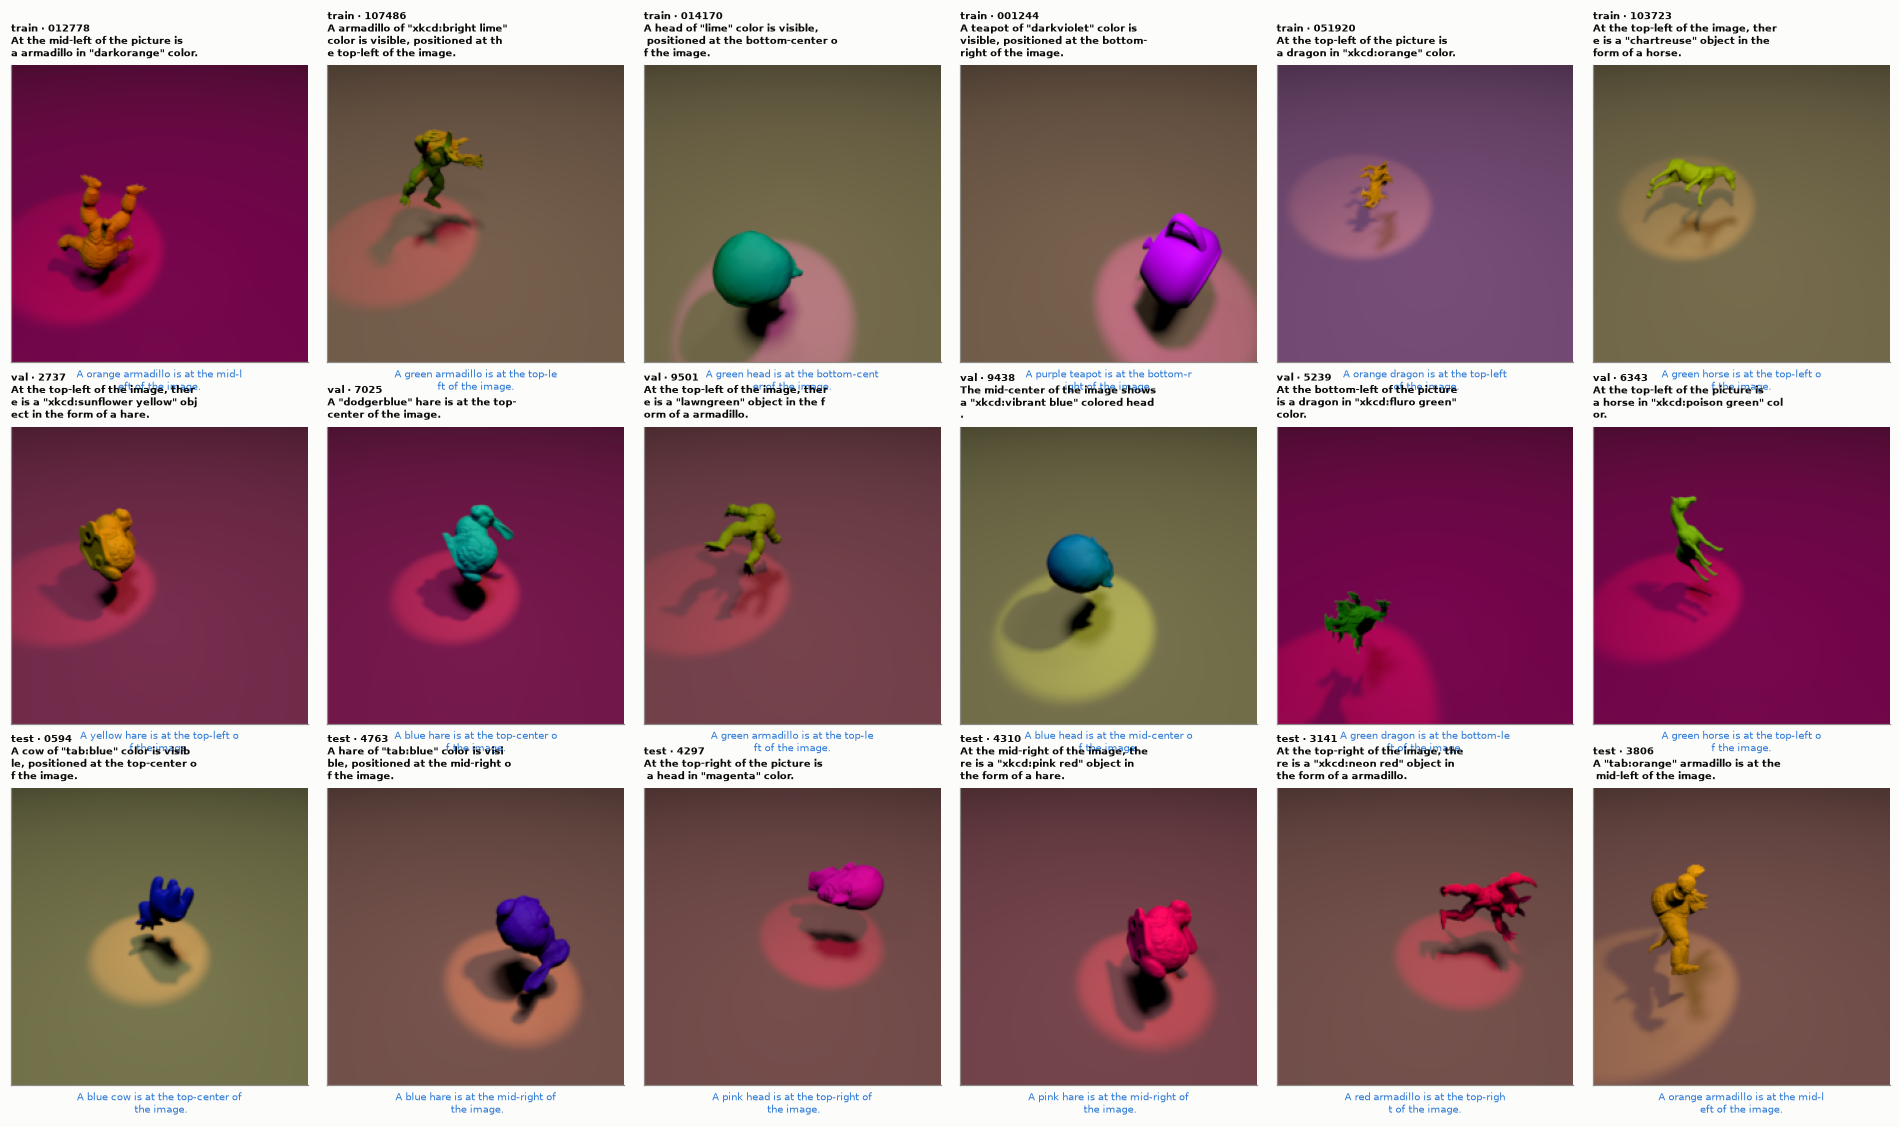

In [ ]:
if IMAGES_OK:
    root = data_root(VARIANT)
    fig, axes = plt.subplots(3, N_IMG_SHOW, figsize=(2.9 * N_IMG_SHOW, 10))
    for r, s in enumerate(SPLITS):
        for c, i in enumerate(rng.choice(len(D[s]), N_IMG_SHOW, replace=False)):
            row = D[s].iloc[int(i)]
            ax = axes[r, c]
            ax.imshow(Image.open(root / row["image_path"]).convert("RGB"))
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            wrap = lambda t, w=34: "\n".join(t[k : k + w] for k in range(0, len(t), w))
            ax.set_title(
                f"{s} · {row['id'].split('/')[-1]}\n{wrap(row['caption'])}",
                fontsize=6.5,
                loc="left",
            )
            ax.set_xlabel(wrap(row["canonical"]), fontsize=6.5, color=SERIES[0])
    fig.tight_layout()
    savefig(fig, "11_galeria_splits")
    plt.show()
else:
    print("Imágenes no disponibles en", data_root(VARIANT), "— se omite la galería.")

## 12. Resumen de hallazgos

Se imprime y se guarda en `reports/tables/eda_splits/hallazgos.md`, listo para el informe.

In [ ]:
lines = ["# Hallazgos del EDA de splits — M3DI base (train / val / test)\n"]
current = None
for sec, txt in FINDINGS:
    if sec != current:
        lines.append(f"\n## {sec}\n")
        current = sec
    lines.append(f"- {txt}")
out_md = TAB_DIR / "hallazgos.md"
out_md.write_text("\n".join(lines) + "\n", encoding="utf-8")
display(Markdown("\n".join(lines)))
print("→", out_md)

# Hallazgos del EDA de splits — M3DI base (train / val / test)


## Integridad

- train/val/test = 125,000 / 10,000 / 10,000 filas; ids únicos, row_idx contiguo y sin nulos/NaN: ✓.
- object_zpos es constante en los tres splits (no aporta información; se excluye).
- imágenes accesibles en disco: sí (raíz C:\Users\bruno\Documents\MDS\Redes_Neuronales_Teoria_Informacion\Proyecto T7\data\raw\m3di); 

## Fuga

- sin ids, rutas ni escenas repetidas entre splits ni dentro de ellos.
- distancia mediana al vecino de train: test 0.2338, val 0.2344, train→train 0.2334 (KS test vs train: D=0.011; val vs train: D=0.012). No hay escenas casi duplicadas: test y val son tan lejanos a train como train de sí mismo.

## Captions

- captions únicos: train 10,936, val 5,372, test 5,385; el 99.4% de las filas de test tiene un caption que aparece literal en train.
- banco de VL-JEPA (20,000 filas de train → 7,492 captions únicos) contiene el caption correcto en el 85.5% de test: techo de la recuperación exacta con el objetivo original. Con el canónico la cobertura es 100.0%.

## Imagen vs texto

- forma, x e y coinciden en el 100 % de las filas de los tres splits: el techo por atributo es 1.

## Discretos

- los seis atributos discretos tienen la misma distribución en los tres splits: V de Cramér máx. 0.0092 (celda (x,y)), JSD máx. 2.86e-04 bits.
- en train: forma H/Hmax=1.000, x H/Hmax=1.000, y H/Hmax=1.000, celda (x,y) H/Hmax=1.000, color básico H/Hmax=0.950, plantilla H/Hmax=1.000. Forma, posición y plantilla son ~uniformes; el color básico no (las 8 categorías cubren arcos de matiz distintos).

## Color

- la frecuencia de cada categoría básica coincide con el ancho de su arco de matiz (desvío máx. 0.0019); va de 6.9% (orange) a 25.0% (green).

## Composicional

- las 63 combinaciones están presentes en los tres splits (mín. train 1,912, val 134, test 126); con el holdout, train pierde 27,643 filas (22.1%, quedan 97,357) y test evalúa 2,219 imágenes de combinaciones no vistas.
- cada forma pierde 2 celdas y cada celda se retira para top-left: 2, top-center: 1, top-right: 2, mid-left: 1, mid-center: 2, mid-right: 1, bottom-left: 2, bottom-center: 1, bottom-right: 2 formas: ninguna forma ni celda desaparece de train.

## Continuos

- los 7 latentes continuos son ~uniformes en [0,1] y homogéneos entre splits (KS train-val/test D máx. 0.0148).
- objeto y fondo con matiz a menos de 18° (camuflaje): train 10.1%, val 10.2%, test 9.8% — lo esperado bajo independencia (10 %).

## Color

- vocabulario de nombres: train 100, val 99, test 99; nombres de val/test ausentes en train: 0.
- H(nombre)=5.96 bits vs H(categoría)=2.85 bits; I(nombre; categoría)=2.50 bits → conociendo la categoría quedan 3.46 bits de incertidumbre sobre el nombre. 78% de los nombres caen siempre en una sola categoría.

## Captions

- longitud media: train 12.93, val 12.91, test 12.91 palabras (rango 10–19); vocabulario: train 114, val 114, test 114; palabras de test ausentes en train: 0.
- objetivo canónico: 231 textos distintos en train (no 7·9·8 = 504: ver §9.1), con 216–1016 filas cada uno; el original: 10,936 textos, 6% de ellos vistos una sola vez.

## Dependencias

- pares con dependencia significativa (G-test, Bonferroni α=0,001): train: x–color básico (NMI 0.706); val: x–color básico (NMI 0.707); test: x–color básico (NMI 0.708). Todos los demás pares tienen NMI < 0.0024 (independientes).
- el matiz del objeto está acotado por x: left [0.000, 0.333], center [0.333, 0.667], right [0.667, 1.000]. Solo 11 de 24 pares (x, color básico) existen → 231 captions canónicos posibles (no 504), lo que coincide con los 231 observados en train.
- atajo: adivinar x a partir del color acierta 80.9% en test (vs 33,3 % sin información) y el color a partir de x 42.5% (vs 24.7% con la clase mayoritaria).

## Azar

- exactitud de azar en test (mayoritario / marginal de train): color 0.247 / 0.152; color ±1 0.430 / 0.382; forma 0.145 / 0.143; nombre exacto 0.058 / 0.023; posición (x,y) 0.116 / 0.111; x 0.343 / 0.333; y 0.333 / 0.333.

→ C:\Users\bruno\Documents\MDS\Redes_Neuronales_Teoria_Informacion\Proyecto T7\reports\tables\eda_splits\hallazgos.md
